<a href="https://colab.research.google.com/github/Mantulisme/SourceCode_ABSA/blob/main/ABSA_Model_Comparison.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# ABSA Model Comparison: BERT vs RoBERTa vs DistilBERT
### Aspect-Category Sentiment Analysis on Steam Game Reviews

This notebook is a Colab-ready version of the full pipeline: data
preprocessing, grouped/stratified k-fold cross-validation, class-weighted
training, and model comparison with significance testing.

**Before running:**
1. `Runtime > Change runtime type > GPU` (T4 is fine)
2. Run cells top to bottom
3. When prompted, upload your `labeled_reviews.json` (Label Studio export)

**Note on runtime:** with the default 5-fold CV over 3 models, this is
15 full training runs. On a free-tier T4 this can take a while —
consider lowering `N_FOLDS` to 3 in the config cell if you're short on
time, or splitting the model loop across multiple sessions (there's a
cell near the bottom for running just one model at a time).


## 1. Environment setup

In [ ]:
import torch
print("CUDA available:", torch.cuda.is_available())
if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
else:
    print("WARNING: no GPU detected. Go to Runtime > Change runtime type > GPU")


CUDA available: True
GPU: Tesla T4


In [ ]:
!pip install -q transformers datasets accelerate scikit-learn pandas numpy matplotlib seaborn scipy


## 2. (Optional but recommended) Mount Google Drive

Colab wipes local files when the runtime disconnects. Mounting Drive
lets you save your processed data and results somewhere that survives
a disconnect — useful given how long the full CV run takes.

Set `USE_DRIVE = False` below if you'd rather keep everything local for
a quick test run (you'll lose it when the runtime recycles).


In [ ]:
USE_DRIVE = True

import os

if USE_DRIVE:
    from google.colab import drive
    drive.mount('/content/drive')
    PROJECT_ROOT = '/content/drive/MyDrive/absa_thesis'
else:
    PROJECT_ROOT = '/content/absa_thesis'

DATA_DIR = os.path.join(PROJECT_ROOT, 'data')
PROCESSED_DIR = os.path.join(DATA_DIR, 'processed')
CHECKPOINT_DIR = os.path.join(PROJECT_ROOT, 'checkpoints')
RESULTS_DIR = os.path.join(PROJECT_ROOT, 'outputs')

for d in [DATA_DIR, PROCESSED_DIR, CHECKPOINT_DIR, RESULTS_DIR]:
    os.makedirs(d, exist_ok=True)

print("Project root:", PROJECT_ROOT)


Mounted at /content/drive
Project root: /content/drive/MyDrive/absa_thesis


## 3. Upload data


In [ ]:
from google.colab import files

RAW_DATA_PATH = os.path.join(DATA_DIR, 'labeled_reviews.json')

if not os.path.exists(RAW_DATA_PATH):
    print("Upload your labeled_reviews.json:")
    uploaded = files.upload()
    fname = list(uploaded.keys())[0]
    os.rename(fname, RAW_DATA_PATH)

print("Using data file:", RAW_DATA_PATH)


Using data file: /content/drive/MyDrive/absa_thesis/data/labeled_reviews.json


## 4. Configuration

Edit these if your setup differs — this is the single source of truth
used by every cell below (mirrors `scripts/config.py` from the
downloadable project version).


In [ ]:
ASPECT_CATEGORIES = [
    "gameplay", "graphics", "price", "performance",
    "story", "sound", "multiplayer", "developer",
]

SENTIMENT_LABELS = ["positive", "negative", "neutral", "conflict", "none"]
LABEL2ID = {label: i for i, label in enumerate(SENTIMENT_LABELS)}
ID2LABEL = {i: label for label, i in LABEL2ID.items()}
NUM_LABELS = len(SENTIMENT_LABELS)

MODELS = {
    "bert":       "bert-base-uncased",
    "roberta":    "roberta-base",
    "distilbert": "distilbert-base-uncased",
}

MAX_SEQ_LEN = 256
BATCH_SIZE = 16
EVAL_BATCH_SIZE = 32
LEARNING_RATE = 2e-5
NUM_EPOCHS = 4
WEIGHT_DECAY = 0.01
WARMUP_RATIO = 0.1
SEED = 42

N_FOLDS = 5
USE_CLASS_WEIGHTS = True

print(f"Config loaded: {len(ASPECT_CATEGORIES)} aspects, {NUM_LABELS} sentiment classes, {N_FOLDS}-fold CV")


Config loaded: 8 aspects, 5 sentiment classes, 5-fold CV


## 5. Data preprocessing

In [ ]:
import json
import pandas as pd
from collections import defaultdict
from sklearn.model_selection import StratifiedGroupKFold


def load_labelstudio_export(path):
    with open(path, "r", encoding="utf-8") as f:
        data = json.load(f)
    if not isinstance(data, list):
        raise ValueError("Expected top-level JSON list of Label Studio task objects.")
    return data


def extract_aspect_sentiments(task):
    aspect_sentiments = defaultdict(set)
    annotations = task.get("annotations", [])
    if not annotations:
        return aspect_sentiments
    result = annotations[0].get("result", [])
    for span in result:
        if span.get("type") != "labels":
            continue
        for raw_label in span.get("value", {}).get("labels", []):
            if " - " not in raw_label:
                continue
            aspect, sentiment = raw_label.rsplit(" - ", 1)
            aspect_sentiments[aspect.strip().lower()].add(sentiment.strip().lower())
    return aspect_sentiments


def resolve_label(sentiments):
    if len(sentiments) == 0:
        return "none"
    if len(sentiments) == 1:
        label = next(iter(sentiments))
        return label if label in SENTIMENT_LABELS else None
    return "conflict"


def explode_to_instances(tasks):
    rows = []
    for task in tasks:
        data_field = task.get("data", {})
        text = (data_field.get("review_text") or "").strip()
        review_id = data_field.get("recommendationid") or str(task.get("id"))
        game = data_field.get("game", "unknown")
        if not text:
            continue
        aspect_sentiments = extract_aspect_sentiments(task)
        for aspect in ASPECT_CATEGORIES:
            label = resolve_label(aspect_sentiments.get(aspect, set()))
            if label is None:
                continue
            rows.append({
                "review_id": review_id, "game": game, "text": text,
                "aspect_category": aspect, "sentiment": label,
                "label_id": LABEL2ID[label],
            })
    return pd.DataFrame(rows)


def review_dominant_sentiment(df):
    priority = {"conflict": 0, "neutral": 1, "negative": 2, "positive": 3, "none": 4}
    return df.groupby("review_id")["sentiment"].agg(lambda g: min(g, key=lambda s: priority.get(s, 99)))


def assign_folds(df):
    review_ids = df["review_id"].unique()
    dominant = review_dominant_sentiment(df).reindex(review_ids)
    sgkf = StratifiedGroupKFold(n_splits=N_FOLDS, shuffle=True, random_state=SEED)
    fold_map = {}
    for fold_id, (_, test_idx) in enumerate(sgkf.split(X=review_ids, y=dominant.values, groups=review_ids)):
        for i in test_idx:
            fold_map[review_ids[i]] = fold_id
    df = df.copy()
    df["fold"] = df["review_id"].map(fold_map)
    return df


print("Loading raw data...")
tasks = load_labelstudio_export(RAW_DATA_PATH)
print(f"Loaded {len(tasks)} labeled tasks.")

df = explode_to_instances(tasks)
print(f"Exploded to {len(df)} (review, aspect) instances across {df['review_id'].nunique()} reviews.")
print("\nSentiment distribution:")
print(df["sentiment"].value_counts())

df = assign_folds(df)
print("\nFold sizes:")
for fold_id in sorted(df["fold"].unique()):
    fold_df = df[df["fold"] == fold_id]
    print(f"  fold {fold_id}: {len(fold_df)} instances, {fold_df['review_id'].nunique()} reviews")

out_path = os.path.join(PROCESSED_DIR, "all_instances.csv")
df.to_csv(out_path, index=False)
print(f"\nSaved to {out_path}")


Loading raw data...
Loaded 2348 labeled tasks.
Exploded to 18784 (review, aspect) instances across 2348 reviews.

Sentiment distribution:
sentiment
none        13831
positive     2352
negative     1834
conflict      584
neutral       183
Name: count, dtype: int64

Fold sizes:
  fold 0: 3760 instances, 470 reviews
  fold 1: 3760 instances, 470 reviews
  fold 2: 3760 instances, 470 reviews
  fold 3: 3752 instances, 469 reviews
  fold 4: 3752 instances, 469 reviews

Saved to /content/drive/MyDrive/absa_thesis/data/processed/all_instances.csv


## 6. Dataset class

In [ ]:
from torch.utils.data import Dataset

class ABSADataset(Dataset):
    def __init__(self, data, tokenizer, max_length=256):
        self.df = data.reset_index(drop=True) if isinstance(data, pd.DataFrame) else pd.read_csv(data)
        self.tokenizer = tokenizer
        self.max_length = max_length

    def __len__(self):
        return len(self.df)

    def __getitem__(self, idx):
        row = self.df.iloc[idx]
        encoding = self.tokenizer(
            str(row["text"]), str(row["aspect_category"]),
            truncation=True, max_length=self.max_length,
            padding="max_length", return_tensors="pt",
        )
        item = {k: v.squeeze(0) for k, v in encoding.items()}
        item["labels"] = torch.tensor(int(row["label_id"]), dtype=torch.long)
        return item


## 7. Training + evaluation functions (k-fold CV, class-weighted loss)

Class weights are computed fresh per training fold (inverse frequency)
so rare classes like `neutral` cost more to get wrong during training,
without ever looking at the held-out test fold's distribution.

Each fold also records **training time**, **inference throughput**, and
**parameter count** — not just F1 — so you can compare models on
efficiency (training cost, inference speed) alongside accuracy in the
comparison section later.


In [ ]:
import numpy as np
import torch.nn as nn
from sklearn.metrics import classification_report, f1_score, precision_recall_fscore_support
from sklearn.utils.class_weight import compute_class_weight
from transformers import AutoModelForSequenceClassification, AutoTokenizer, Trainer, TrainingArguments, set_seed


class WeightedLossTrainer(Trainer):
    def __init__(self, *args, class_weights=None, **kwargs):
        super().__init__(*args, **kwargs)
        self.class_weights = class_weights

    def compute_loss(self, model, inputs, return_outputs=False, **kwargs):
        labels = inputs.pop("labels")
        outputs = model(**inputs)
        logits = outputs.logits
        weight = self.class_weights.to(logits.device) if self.class_weights is not None else None
        loss_fct = nn.CrossEntropyLoss(weight=weight)
        loss = loss_fct(logits.view(-1, NUM_LABELS), labels.view(-1))
        return (loss, outputs) if return_outputs else loss


def compute_metrics(eval_pred):
    logits, labels = eval_pred
    preds = np.argmax(logits, axis=1)
    precision, recall, _, _ = precision_recall_fscore_support(labels, preds, average="macro", zero_division=0)
    return {
        "accuracy": (preds == labels).mean(),
        "f1_macro": f1_score(labels, preds, average="macro", zero_division=0),
        "f1_weighted": f1_score(labels, preds, average="weighted", zero_division=0),
        "precision_macro": precision,
        "recall_macro": recall,
    }


def get_class_weights(train_df):
    weights = compute_class_weight(
        class_weight="balanced", classes=np.arange(NUM_LABELS), y=train_df["label_id"].values,
    )
    return torch.tensor(weights, dtype=torch.float)


def run_fold(model_key, fold_id, df, save_checkpoint=False):
    model_name = MODELS[model_key]
    print(f"\n{'='*60}\n{model_key} — fold {fold_id}/{N_FOLDS - 1}\n{'='*60}")

    train_df = df[df["fold"] != fold_id].reset_index(drop=True)
    test_df = df[df["fold"] == fold_id].reset_index(drop=True)
    print(f"Train: {len(train_df)} | Test (held-out fold): {len(test_df)}")

    tokenizer = AutoTokenizer.from_pretrained(model_name)
    model = AutoModelForSequenceClassification.from_pretrained(
        model_name, num_labels=NUM_LABELS, id2label=ID2LABEL, label2id=LABEL2ID,
    )
    n_parameters = sum(p.numel() for p in model.parameters())
    n_trainable_parameters = sum(p.numel() for p in model.parameters() if p.requires_grad)

    train_dataset = ABSADataset(train_df, tokenizer, MAX_SEQ_LEN)
    test_dataset = ABSADataset(test_df, tokenizer, MAX_SEQ_LEN)
    class_weights = get_class_weights(train_df) if USE_CLASS_WEIGHTS else None

    output_dir = os.path.join(CHECKPOINT_DIR, model_key, f"fold{fold_id}")
    os.makedirs(output_dir, exist_ok=True)

    training_args = TrainingArguments(
        output_dir=output_dir,
        num_train_epochs=NUM_EPOCHS,
        per_device_train_batch_size=BATCH_SIZE,
        per_device_eval_batch_size=EVAL_BATCH_SIZE,
        learning_rate=LEARNING_RATE,
        weight_decay=WEIGHT_DECAY,
        warmup_ratio=WARMUP_RATIO,
        eval_strategy="epoch",
        save_strategy="epoch" if save_checkpoint else "no",
        load_best_model_at_end=save_checkpoint,
        metric_for_best_model="f1_macro" if save_checkpoint else None,
        greater_is_better=True,
        save_total_limit=1,
        logging_steps=50,
        report_to="none",
        seed=SEED,
        fp16=torch.cuda.is_available(),
    )

    trainer = WeightedLossTrainer(
        model=model, args=training_args, train_dataset=train_dataset,
        eval_dataset=test_dataset, compute_metrics=compute_metrics, class_weights=class_weights,
    )
    train_result = trainer.train()
    train_metrics = train_result.metrics  # includes train_runtime, train_samples_per_second
    eval_result = trainer.evaluate()      # includes eval_runtime, eval_samples_per_second

    pred_output = trainer.predict(test_dataset)
    preds = np.argmax(pred_output.predictions, axis=1)
    labels = pred_output.label_ids
    report = classification_report(
        labels, preds, labels=list(range(NUM_LABELS)),
        target_names=SENTIMENT_LABELS, output_dict=True, zero_division=0,
    )

    test_df = test_df.copy()
    test_df["pred"] = preds
    per_aspect = {
        aspect: {
            "n": len(group),
            "f1_macro": f1_score(group["label_id"], group["pred"], average="macro", zero_division=0),
            "f1_weighted": f1_score(group["label_id"], group["pred"], average="weighted", zero_division=0),
        }
        for aspect, group in test_df.groupby("aspect_category")
    }

    if save_checkpoint:
        trainer.save_model(output_dir)
        tokenizer.save_pretrained(output_dir)
    else:
        import shutil
        shutil.rmtree(output_dir, ignore_errors=True)

    return {
        "fold": fold_id, "n_train": len(train_df), "n_test": len(test_df),
        "eval_metrics": {k: float(v) for k, v in eval_result.items()},
        "classification_report": report, "per_aspect_breakdown": per_aspect,
        "n_parameters": n_parameters,
        "n_trainable_parameters": n_trainable_parameters,
        "train_runtime_seconds": train_metrics.get("train_runtime"),
        "train_samples_per_second": train_metrics.get("train_samples_per_second"),
        "eval_runtime_seconds": eval_result.get("eval_runtime"),
        "eval_samples_per_second": eval_result.get("eval_samples_per_second"),
    }


def run_cv(model_key, df, folds_to_run=None, save_checkpoints=False):
    set_seed(SEED)
    folds_to_run = folds_to_run if folds_to_run is not None else list(range(N_FOLDS))
    fold_results = []
    for fold_id in folds_to_run:
        result = run_fold(model_key, fold_id, df, save_checkpoints)
        fold_results.append(result)
        time_str = f" | Train time: {result['train_runtime_seconds']/60:.1f} min" if result["train_runtime_seconds"] else ""
        print(f"Fold {fold_id} — F1-macro: {result['eval_metrics']['eval_f1_macro']:.4f} | "
              f"F1-weighted: {result['eval_metrics']['eval_f1_weighted']:.4f}{time_str}")

    f1_macros = [r["eval_metrics"]["eval_f1_macro"] for r in fold_results]
    f1_weighteds = [r["eval_metrics"]["eval_f1_weighted"] for r in fold_results]
    train_times = [r["train_runtime_seconds"] for r in fold_results if r["train_runtime_seconds"] is not None]
    eval_throughputs = [r["eval_samples_per_second"] for r in fold_results if r["eval_samples_per_second"] is not None]

    summary = {
        "model_key": model_key, "model_name": MODELS[model_key], "n_folds": len(fold_results),
        "f1_macro_mean": float(np.mean(f1_macros)), "f1_macro_std": float(np.std(f1_macros)),
        "f1_weighted_mean": float(np.mean(f1_weighteds)), "f1_weighted_std": float(np.std(f1_weighteds)),
        "n_parameters": fold_results[0]["n_parameters"],
        "n_trainable_parameters": fold_results[0]["n_trainable_parameters"],
        "train_time_mean_seconds": float(np.mean(train_times)) if train_times else None,
        "train_time_std_seconds": float(np.std(train_times)) if train_times else None,
        "train_time_total_seconds": float(np.sum(train_times)) if train_times else None,
        "eval_samples_per_second_mean": float(np.mean(eval_throughputs)) if eval_throughputs else None,
        "fold_results": fold_results,
    }
    out_path = os.path.join(RESULTS_DIR, f"{model_key}_cv_results.json")
    with open(out_path, "w") as f:
        json.dump(summary, f, indent=2)
    print(f"\n{'='*60}\n{model_key} — {len(fold_results)}-fold CV summary")
    print(f"F1-macro:    {summary['f1_macro_mean']:.4f} ± {summary['f1_macro_std']:.4f}")
    print(f"F1-weighted: {summary['f1_weighted_mean']:.4f} ± {summary['f1_weighted_std']:.4f}")
    if summary["train_time_mean_seconds"]:
        print(f"Train time:  {summary['train_time_mean_seconds']/60:.1f} min/fold "
              f"(total: {summary['train_time_total_seconds']/60:.1f} min)")
    print(f"Parameters:  {summary['n_parameters']:,}")
    print(f"Saved to {out_path}")
    return summary


## 8. Run cross-validation for each model

Runs all `N_FOLDS` folds for each backbone. This is the slow part —
expect this to take a while on a T4. If your session disconnects
partway through, you can re-run just the remaining model(s); already
mounted Drive results won't be lost.

**Tip:** if you're short on Colab time, run one model per cell/session
using the single-model cell further below instead of this loop.


In [ ]:
df = pd.read_csv(os.path.join(PROCESSED_DIR, "all_instances.csv"))

all_summaries = {}
for model_key in MODELS:
    all_summaries[model_key] = run_cv(model_key, df)


### Alternative: run one model at a time

Use this instead of the loop above if you want to split the work across
multiple Colab sessions.


In [ ]:
# Uncomment and set the model you want to train this session
summary = run_cv("bert", df)


bert — fold 0/4
Train: 15024 | Test (held-out fold): 3760


config.json:   0%|          | 0.00/570 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

...

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertForSequenceClassification LOAD REPORT from: bert-base-uncased
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.seq_relationship.weight                | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
cls.seq_relationship.bias                  | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
classifier.weight                          | MISSING    | 
classifier.bias                            | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.
[transformers] warmup_

Epoch,Training Loss,Validation Loss,Accuracy,F1 Macro,F1 Weighted,Precision Macro,Recall Macro
1,1.083781,1.052929,0.777452,0.506947,0.793369,0.488994,0.573840
2,0.816341,0.962917,0.808902,0.573628,0.820678,0.627578,0.604676
3,0.607220,0.960617,0.837687,0.606723,0.846283,0.584185,0.649849
4,0.479318,1.019522,0.846215,0.612867,0.853132,0.588458,0.649602


Training Loss,Validation Loss,Epoch,Accuracy,F1 Macro,F1 Weighted,Precision Macro,Recall Macro
0.479318,1.019522,4,0.846215,0.612867,0.853132,0.588458,0.649602


Fold 4 — F1-macro: 0.6129 | F1-weighted: 0.8531 | Train time: 14.8 min

bert — 5-fold CV summary
F1-macro:    0.6188 ± 0.0116
F1-weighted: 0.8552 ± 0.0096
Train time:  14.8 min/fold (total: 74.0 min)
Parameters:  109,486,085
Saved to /content/drive/MyDrive/absa_thesis/outputs/bert_cv_results.json


In [ ]:
summary = run_cv("roberta", df)


roberta — fold 0/4
Train: 15024 | Test (held-out fold): 3760


config.json:   0%|          | 0.00/481 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/25.0 [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/899k [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/456k [00:00<?, ?B/s]

...

Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

[transformers] RobertaForSequenceClassification LOAD REPORT from: roberta-base
Key                        | Status     | 
---------------------------+------------+-
lm_head.layer_norm.bias    | UNEXPECTED | 
lm_head.layer_norm.weight  | UNEXPECTED | 
lm_head.bias               | UNEXPECTED | 
lm_head.dense.bias         | UNEXPECTED | 
lm_head.dense.weight       | UNEXPECTED | 
classifier.out_proj.weight | MISSING    | 
classifier.out_proj.bias   | MISSING    | 
classifier.dense.weight    | MISSING    | 
classifier.dense.bias      | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.
[transformers] warmup_ratio is deprecated and will be removed in v5.2. Use `warmup_steps` instead.


Epoch,Training Loss,Validation Loss,Accuracy,F1 Macro,F1 Weighted,Precision Macro,Recall Macro
1,1.104166,1.115515,0.731343,0.426010,0.759982,0.432585,0.529058
2,0.842902,0.995412,0.832623,0.578927,0.840103,0.577444,0.601891
3,0.631460,0.979767,0.845682,0.610708,0.853950,0.576551,0.662217
4,0.524480,1.094414,0.864072,0.629622,0.868110,0.611758,0.656863


Training Loss,Validation Loss,Epoch,Accuracy,F1 Macro,F1 Weighted,Precision Macro,Recall Macro
0.524480,1.094414,4,0.864072,0.629622,0.868110,0.611758,0.656863


Fold 4 — F1-macro: 0.6296 | F1-weighted: 0.8681 | Train time: 14.8 min

roberta — 5-fold CV summary
F1-macro:    0.6253 ± 0.0078
F1-weighted: 0.8613 ± 0.0068
Train time:  14.9 min/fold (total: 74.3 min)
Parameters:  124,649,477
Saved to /content/drive/MyDrive/absa_thesis/outputs/roberta_cv_results.json


In [ ]:
summary = run_cv("distilbert", df)


distilbert — fold 0/4
Train: 15024 | Test (held-out fold): 3760


config.json:   0%|          | 0.00/483 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

...

Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

[transformers] DistilBertForSequenceClassification LOAD REPORT from: distilbert-base-uncased
Key                     | Status     | 
------------------------+------------+-
vocab_layer_norm.bias   | UNEXPECTED | 
vocab_transform.weight  | UNEXPECTED | 
vocab_transform.bias    | UNEXPECTED | 
vocab_projector.bias    | UNEXPECTED | 
vocab_layer_norm.weight | UNEXPECTED | 
pre_classifier.weight   | MISSING    | 
pre_classifier.bias     | MISSING    | 
classifier.weight       | MISSING    | 
classifier.bias         | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.
[transformers] warmup_ratio is deprecated and will be removed in v5.2. Use `warmup_steps` instead.


Epoch,Training Loss,Validation Loss,Accuracy,F1 Macro,F1 Weighted,Precision Macro,Recall Macro
1,1.121569,1.053932,0.724680,0.470789,0.754023,0.442540,0.574375
2,0.861283,1.021051,0.778518,0.519222,0.794589,0.493240,0.579114
3,0.722223,1.021674,0.786780,0.543517,0.802907,0.507607,0.615068
4,0.660998,1.077391,0.810768,0.569579,0.821790,0.546353,0.613893


Training Loss,Validation Loss,Epoch,Accuracy,F1 Macro,F1 Weighted,Precision Macro,Recall Macro
0.660998,1.077391,4,0.810768,0.569579,0.821790,0.546353,0.613893


Fold 4 — F1-macro: 0.5696 | F1-weighted: 0.8218 | Train time: 7.8 min

distilbert — 5-fold CV summary
F1-macro:    0.5764 ± 0.0040
F1-weighted: 0.8264 ± 0.0024
Train time:  7.9 min/fold (total: 39.3 min)
Parameters:  66,957,317
Saved to /content/drive/MyDrive/absa_thesis/outputs/distilbert_cv_results.json


## 9. Compare results

Aggregates F1-macro/weighted (mean ± std) across all trained models and
runs paired significance tests on fold-level scores.

**Important:** with `N_FOLDS=5`, the Wilcoxon signed-rank test below has
a hard floor at p=0.0625 and can never show significance, regardless of
true effect size (it's a property of the exact test with few paired
samples, not a bug). A paired t-test is reported alongside it since it
doesn't have this floor — but it assumes roughly normal fold-level
differences, a shakier assumption with only ~5 folds. For your thesis:
report both, note the Wilcoxon floor explicitly, and lean on the raw
mean ± std differences for your discussion rather than a significance
claim alone. Set `N_FOLDS=10` earlier and re-run if you want a realistic
shot at significance.


     model              model_name  n_folds  f1_macro_mean  f1_macro_std  f1_weighted_mean  f1_weighted_std  n_parameters  train_time_mean_min  train_time_total_min eval_samples_per_second_mean
      bert       bert-base-uncased        5       0.618782      0.011602          0.855197         0.009565     109486085            14.804469             74.022347                         None
   roberta            roberta-base        5       0.625281      0.007792          0.861315         0.006767     124649477            14.861188             74.305942                         None
distilbert distilbert-base-uncased        5       0.576444      0.004045          0.826387         0.002434      66957317             7.862281             39.311405                         None


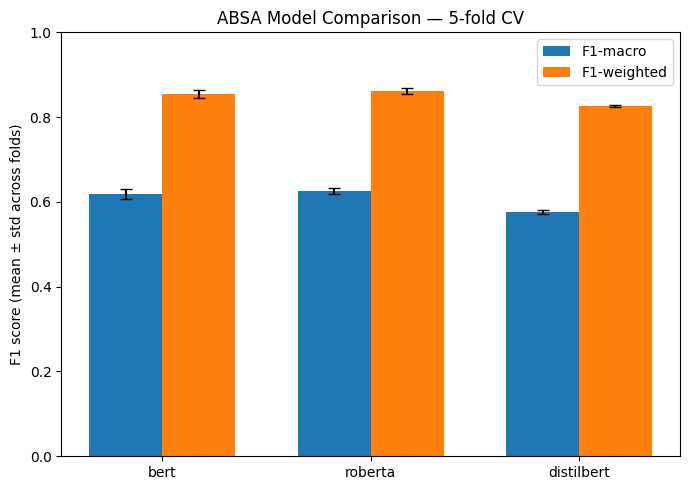


=== Efficiency summary ===
     model n_parameters  train_time_mean_min  train_time_total_min eval_samples_per_second_mean  f1_macro_mean
      bert         109M                 14.8                  74.0                         None       0.618782
   roberta         125M                 14.9                  74.3                         None       0.625281
distilbert          67M                  7.9                  39.3                         None       0.576444
(train_time_mean_min = avg training time per fold; train_time_total_min = sum across all folds; eval_samples_per_second_mean = inference throughput, higher is faster — relevant for deployment speed, not just training cost)


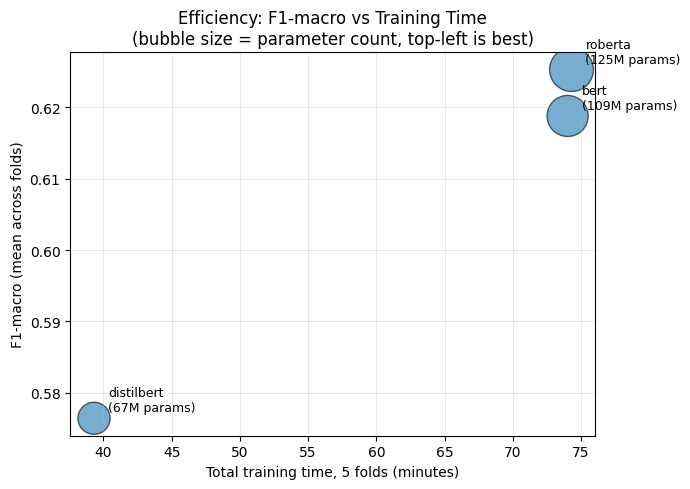


bert_vs_roberta: mean diff = -0.0065
  Wilcoxon: p=0.3125 (floor at n=5: 0.0625)
  Paired t-test: p=0.3155 (not significant)

bert_vs_distilbert: mean diff = +0.0423
  Wilcoxon: p=0.0625 (floor at n=5: 0.0625)
  Paired t-test: p=0.0008 (SIGNIFICANT)

roberta_vs_distilbert: mean diff = +0.0488
  Wilcoxon: p=0.0625 (floor at n=5: 0.0625)
  Paired t-test: p=0.0003 (SIGNIFICANT)


In [ ]:
import itertools
import matplotlib.pyplot as plt
from scipy.stats import wilcoxon, ttest_rel

def load_all_results():
    summaries, per_fold = [], {}
    for key in MODELS:
        path = os.path.join(RESULTS_DIR, f"{key}_cv_results.json")
        if not os.path.exists(path):
            print(f"[WARN] Missing results for '{key}', skipping.")
            continue
        with open(path) as f:
            r = json.load(f)
        summaries.append({
            "model": key, "model_name": r["model_name"], "n_folds": r["n_folds"],
            "f1_macro_mean": r["f1_macro_mean"], "f1_macro_std": r["f1_macro_std"],
            "f1_weighted_mean": r["f1_weighted_mean"], "f1_weighted_std": r["f1_weighted_std"],
            "n_parameters": r.get("n_parameters"),
            "train_time_mean_min": (r["train_time_mean_seconds"] / 60) if r.get("train_time_mean_seconds") else None,
            "train_time_total_min": (r["train_time_total_seconds"] / 60) if r.get("train_time_total_seconds") else None,
            "eval_samples_per_second_mean": r.get("eval_samples_per_second_mean"),
        })
        fold_scores = sorted(r["fold_results"], key=lambda x: x["fold"])
        per_fold[key] = {
            "f1_macro": [fr["eval_metrics"]["eval_f1_macro"] for fr in fold_scores],
            "f1_weighted": [fr["eval_metrics"]["eval_f1_weighted"] for fr in fold_scores],
        }
    return pd.DataFrame(summaries), per_fold


def pairwise_significance(per_fold, metric="f1_macro"):
    results = {}
    model_keys = list(per_fold.keys())
    n_folds = len(next(iter(per_fold.values()))[metric])
    for m1, m2 in itertools.combinations(model_keys, 2):
        s1, s2 = np.array(per_fold[m1][metric]), np.array(per_fold[m2][metric])
        diffs = s1 - s2
        entry = {"mean_diff": float(np.mean(diffs)), "n_folds": n_folds}
        if np.allclose(diffs, 0):
            entry["note"] = "identical scores across all folds"
        else:
            try:
                w_stat, w_p = wilcoxon(s1, s2)
                entry["wilcoxon"] = {"p_value": float(w_p), "significant_at_0.05": bool(w_p < 0.05),
                                      "min_possible_p_at_this_n": 2 / (2 ** n_folds)}
            except ValueError as e:
                entry["wilcoxon"] = {"error": str(e)}
            t_stat, t_p = ttest_rel(s1, s2)
            entry["paired_t_test"] = {"p_value": float(t_p), "significant_at_0.05": bool(t_p < 0.05)}
        results[f"{m1}_vs_{m2}"] = entry
    return results


df_summary, per_fold = load_all_results()
print(df_summary.to_string(index=False))
df_summary.to_csv(os.path.join(RESULTS_DIR, "model_comparison.csv"), index=False)

# Chart
fig, ax = plt.subplots(figsize=(7, 5))
x = np.arange(len(df_summary))
width = 0.35
ax.bar(x - width/2, df_summary["f1_macro_mean"], width, yerr=df_summary["f1_macro_std"], capsize=4, label="F1-macro")
ax.bar(x + width/2, df_summary["f1_weighted_mean"], width, yerr=df_summary["f1_weighted_std"], capsize=4, label="F1-weighted")
ax.set_xticks(x); ax.set_xticklabels(df_summary["model"])
ax.set_ylabel("F1 score (mean ± std across folds)")
ax.set_ylim(0, 1)
ax.set_title(f"ABSA Model Comparison — {N_FOLDS}-fold CV")
ax.legend()
plt.tight_layout()
plt.savefig(os.path.join(RESULTS_DIR, "model_comparison.png"), dpi=150)
plt.show()

# --- Efficiency table + chart: F1 vs training time (the "which is most efficient" view) ---
print("\n=== Efficiency summary ===")
eff_cols = ["model", "n_parameters", "train_time_mean_min", "train_time_total_min",
            "eval_samples_per_second_mean", "f1_macro_mean"]
eff_df = df_summary[eff_cols].copy()
eff_df["n_parameters"] = eff_df["n_parameters"].apply(lambda x: f"{x/1e6:.0f}M" if pd.notna(x) else "n/a")
for c in ["train_time_mean_min", "train_time_total_min", "eval_samples_per_second_mean"]:
    eff_df[c] = eff_df[c].round(1)
print(eff_df.to_string(index=False))
print("(train_time_mean_min = avg training time per fold; train_time_total_min = sum "
      "across all folds; eval_samples_per_second_mean = inference throughput, higher "
      "is faster — relevant for deployment speed, not just training cost)")

if not df_summary["train_time_total_min"].isna().all():
    fig2, ax2 = plt.subplots(figsize=(7, 5))
    sizes = (df_summary["n_parameters"].fillna(df_summary["n_parameters"].median()) / 1e6) * 8
    ax2.scatter(df_summary["train_time_total_min"], df_summary["f1_macro_mean"], s=sizes, alpha=0.6, edgecolors="black")
    for _, row in df_summary.iterrows():
        label = row["model"]
        if pd.notna(row["n_parameters"]):
            label += f"\n({row['n_parameters']/1e6:.0f}M params)"
        ax2.annotate(label, (row["train_time_total_min"], row["f1_macro_mean"]), textcoords="offset points", xytext=(10, 5), fontsize=9)
    ax2.set_xlabel(f"Total training time, {N_FOLDS} folds (minutes)")
    ax2.set_ylabel("F1-macro (mean across folds)")
    ax2.set_title("Efficiency: F1-macro vs Training Time\n(bubble size = parameter count, top-left is best)")
    ax2.grid(alpha=0.3)
    plt.tight_layout()
    plt.savefig(os.path.join(RESULTS_DIR, "efficiency_comparison.png"), dpi=150)
    plt.show()
else:
    print("[WARN] No training time data found — results from before the timing patch "
          "won't have this. Re-run train_cv/run_cv to capture it.")

if len(df_summary) >= 2:
    sig_results = pairwise_significance(per_fold, metric="f1_macro")
    with open(os.path.join(RESULTS_DIR, "significance_tests.json"), "w") as f:
        json.dump(sig_results, f, indent=2)
    for pair, res in sig_results.items():
        print(f"\n{pair}: mean diff = {res.get('mean_diff', 0):+.4f}")
        if "wilcoxon" in res and "p_value" in res["wilcoxon"]:
            w = res["wilcoxon"]
            print(f"  Wilcoxon: p={w['p_value']:.4f} (floor at n={N_FOLDS}: {w['min_possible_p_at_this_n']:.4f})")
        if "paired_t_test" in res:
            t = res["paired_t_test"]
            print(f"  Paired t-test: p={t['p_value']:.4f} ({'SIGNIFICANT' if t['significant_at_0.05'] else 'not significant'})")


## 10. Download your results

If you didn't mount Drive, use this to download the outputs folder
before your Colab session ends (local files disappear on disconnect).


In [ ]:
import shutil
if not USE_DRIVE:
    shutil.make_archive('/content/absa_outputs', 'zip', RESULTS_DIR)
    files.download('/content/absa_outputs.zip')
else:
    print(f"Results are saved to your Drive at: {RESULTS_DIR}")
